# ML CSAI500 Module 2 In-Class Activity

## End-to-End Machine Learning Workflow

**Student version - approximately 30 minutes**

Work in pairs. Read every instruction, complete the TODOs, run the cells, and record what you observe. The hints guide you without giving every answer.

## Setup and dataset

This activity uses the California housing regression problem from Geron's notebook. The first run may download the dataset. If the download fails, use Google Colab or check your internet connection.

In [1]:
# Install once if needed:
# %pip install pandas numpy matplotlib scikit-learn joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error
pd.set_option('display.max_columns',20)
RANDOM_STATE=42

In [15]:
# California housing is a regression problem: predict median house value.
# The first run may download the data.
housing=fetch_california_housing(as_frame=True)
df=housing.frame.copy()
print('Shape:',df.shape)
display(df.head())

Shape: (20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


## Updated activity structure

The first tasks are the core 30-minute activity. The final sections are optional extensions. Use the comments and hints, but explain your observations in your own words.

## Core Task 0 - Data quality and data types

Inspect missing values, duplicates, unusual values, and categorical variables. Do not automatically delete the age value 190; discuss whether it is an error or a rare valid case.

In [7]:
quality_demo=pd.DataFrame({'Age':[22,35,np.nan,41,190],'Income':[42000,68000,52000,np.nan,71000],'Plan':['Basic','Premium','Basic','Premium','Unknown']})
# TODO: display the table.
display(quality_demo)
# TODO: count missing values, duplicate rows, and inspect data types.
# Contar valores ausentes por coluna
print('Valores ausentes:')
print(quality_demo.isna().sum())
# Contar filas duplicadas
print('Filas duplicadas:')
print(quality_demo.duplicated().sum())
# Inspeccionar tipos de datos
print('Tipos de datos:')
print(quality_demo.dtypes)
print('Complete the inspection steps.')
# Inspecionar valores numéricos incomuns
display(quality_demo.describe())
print('\nCategorias de Plan:')
print(quality_demo['Plan'].value_counts(dropna=False))

,Age,Income,Plan
0,22.0,42000.0,Basic
1,35.0,68000.0,Premium
2,NaN,52000.0,Basic
3,41.0,NaN,Premium
4,190.0,71000.0,Unknown


Valores ausentes:
Age       1
Income    1
Plan      0
dtype: int64
Filas duplicadas:
0
Tipos de datos:
Age       float64
Income    float64
Plan          str
dtype: object
Complete the inspection steps.


,Age,Income
count,4.000000,4.000000
mean,72.000000,58250.000000
std,79.065374,13671.747023
min,22.000000,42000.000000
25%,31.750000,49500.000000
50%,38.000000,60000.000000
75%,78.250000,68750.000000
max,190.000000,71000.000000



Categorias de Plan:
Plan
Basic      2
Premium    2
Unknown    1
Name: count, dtype: int64


## Core Task 1 - Classification metrics

Accuracy is not always enough. Precision matters when false positives are costly; recall matters when missing a positive case is costly; F1 balances precision and recall.

Identify TP, TN, FP, and FN from the actual and predicted lists.

In [12]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
actual=[1,1,1,1,0,0,0,0]
predicted=[1,1,0,1,1,0,0,0]
# TODO: import accuracy, precision, recall, F1, and confusion-matrix functions.
# TODO: print each metric and the confusion matrix.
print('Accuracy :', accuracy_score(actual, predicted))
print('Precision:', precision_score(actual, predicted))
print('Recall   :', recall_score(actual, predicted))
print('F1 score :', f1_score(actual, predicted))
print('Confusion Matrix:')
print(confusion_matrix(actual, predicted))
print('Complete the metric calculations.')

Accuracy : 0.75
Precision: 0.75
Recall   : 0.75
F1 score : 0.75
Confusion Matrix:
[[3 1]
 [1 3]]
Complete the metric calculations.


## Optional Extension - One-hot encoding and scaling

Nominal categories should not usually be encoded as arbitrary numbers. One-hot encoding creates binary features. Normalization maps values to a fixed range; standardization centers values around zero. Complete the experiment using the hints in the code.

In [13]:
from sklearn.preprocessing import LabelEncoder, MinMaxScaler

category_demo=pd.DataFrame({'Income':[25000,50000,90000,70000],'Color':['Red','Blue','Green','Red']})
# TODO: create and fit an encoder for Color.
le = LabelEncoder()
category_demo['Color'] = le.fit_transform(category_demo['Color'])
# TODO: create a DataFrame from the encoded values.
category_demo_encoded = pd.DataFrame(category_demo)
# TODO: apply MinMaxScaler and StandardScaler to Income.

minmax_scaler = MinMaxScaler()
standard_scaler = StandardScaler()
category_demo_encoded['Income'] = minmax_scaler.fit_transform(category_demo_encoded[['Income']])
category_demo_encoded['Income'] = standard_scaler.fit_transform(category_demo_encoded[['Income']])
print('Complete the encoding and scaling experiment.')
print(category_demo_encoded)

Complete the encoding and scaling experiment.
     Income  Color
0 -1.401770      2
1 -0.363422      0
2  1.297935      1
3  0.467257      2


## Activity 1 - Inspect the data

Print the shape, display the first rows, run `info()`, display summary statistics, and check missing values.

**Hints:** Use `df.shape`, `df.head()`, `df.info()`, `df.describe()`, and `df.isna().sum()`. Explain what each output tells you.

In [22]:
print('Shape:', df.shape)
print('Columns:', df.columns)
print('Data types:', df.dtypes)
print('Missing values per column:\n', df.isna().sum())
print('Duplicate rows:', df.duplicated().sum())
print('Summary statistics:\n', df.describe())
print('Unique values per column:\n', df.nunique())
display(df.head())

Shape: (20640, 9)
Columns: Index(['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup',
       'Latitude', 'Longitude', 'MedHouseVal'],
      dtype='str')
Data types: MedInc         float64
HouseAge       float64
AveRooms       float64
AveBedrms      float64
Population     float64
AveOccup       float64
Latitude       float64
Longitude      float64
MedHouseVal    float64
dtype: object
Missing values per column:
 MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64
Duplicate rows: 0
Summary statistics:
              MedInc      HouseAge      AveRooms     AveBedrms    Population  \
count  20640.000000  20640.000000  20640.000000  20640.000000  20640.000000   
mean       3.870671     28.639486      5.429000      1.096675   1425.476744   
std        1.899822     12.585558      2.474173      0.473911   1132.462122   
min        0.499900      1.000000      0.846

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


## Activity 2 - Explore distributions and relationships

Plot histograms and compute correlations with `MedHouseVal`. Identify one strong relationship and one warning sign.

**Hint:** Use `df.hist(...)` and `df.corr(numeric_only=True)`. Correlation is not causation.

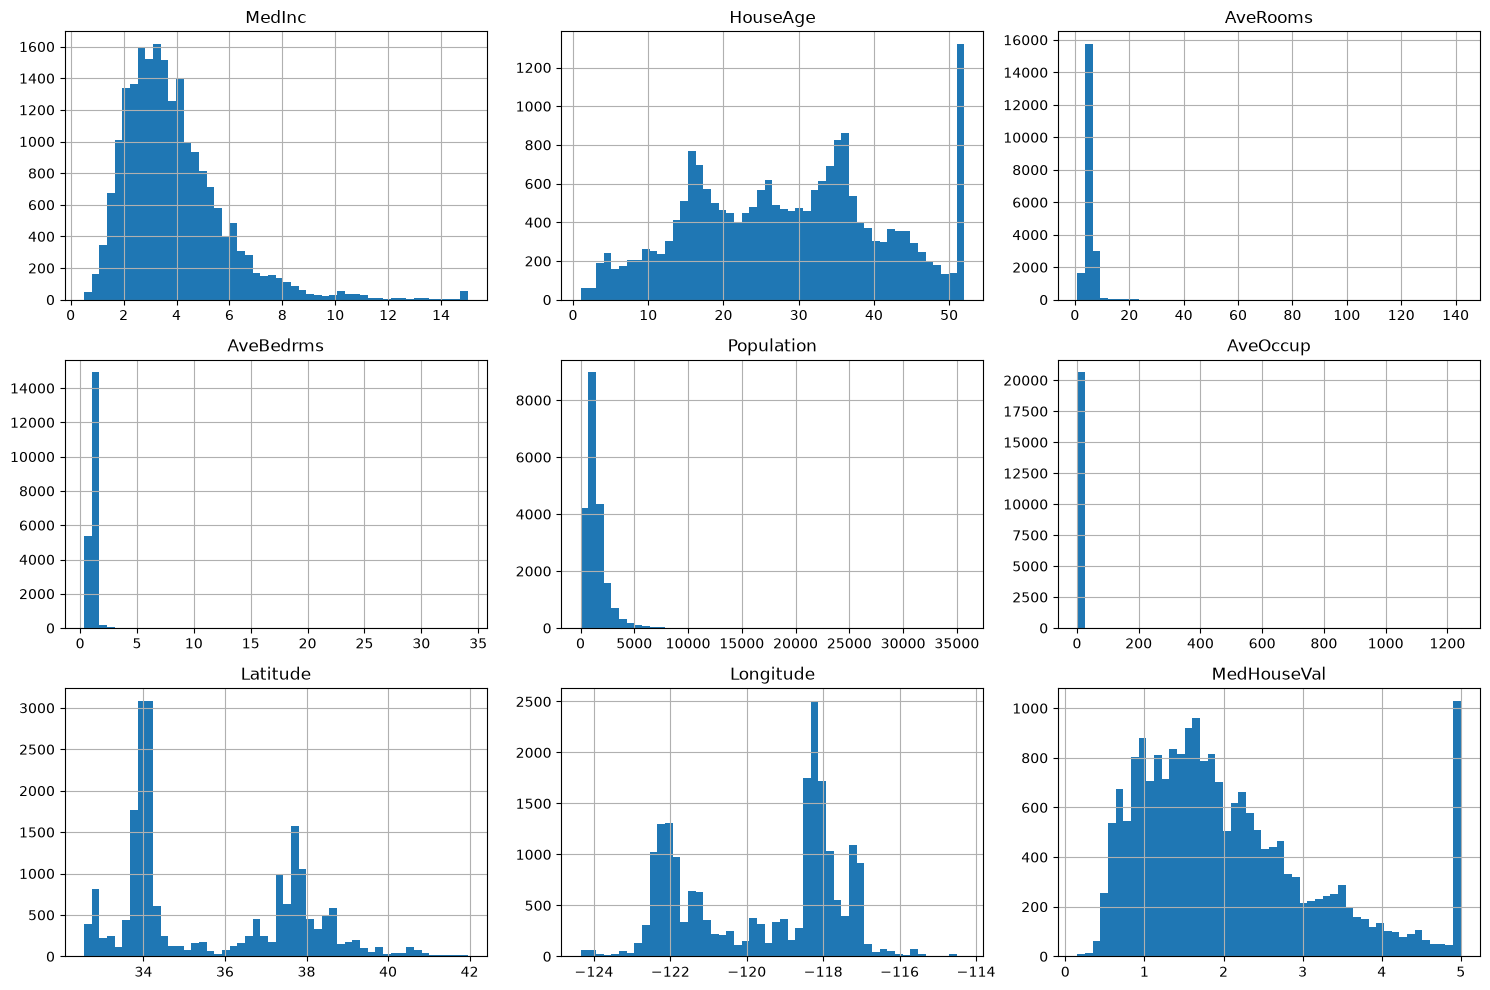

MedHouseVal    1.000000
MedInc         0.688075
AveRooms       0.151948
HouseAge       0.105623
AveOccup      -0.023737
Population    -0.024650
Longitude     -0.045967
AveBedrms     -0.046701
Latitude      -0.144160
Name: MedHouseVal, dtype: float64


In [23]:
# Histogramas: mostram como os valores de cada coluna se distribuem
df.hist(bins=50, figsize=(15, 10))
plt.tight_layout()
plt.show()

# Correlação de cada variável com o valor das casas
correlations = df.corr(numeric_only=True)['MedHouseVal']
print(correlations.sort_values(ascending=False))

## Activity 3 - Create a train/test split

Create `X` without the target and `y` containing the target. Use an 80/20 split with `random_state=42`.

**Why?** The test data must remain unseen until final evaluation.

In [24]:
from sklearn.model_selection import train_test_split

X = df.drop(columns='MedHouseVal')
y = df['MedHouseVal']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print('X_train:', X_train.shape)
print('X_test:', X_test.shape)
print('y_train:', y_train.shape)
print('y_test:', y_test.shape)

X_train: (16512, 8)
X_test: (4128, 8)
y_train: (16512,)
y_test: (4128,)


## Activity 4 - Build a preprocessing pipeline

Build a pipeline with median imputation and standard scaling. Fit the preprocessor on training data only, then transform training and test data.

**Question:** Why is fitting on the entire dataset a leakage risk?

In [25]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer

numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

preprocessor = ColumnTransformer([
    ('numeric', numeric_pipeline, list(X.columns))
])

X_train_prepared = preprocessor.fit_transform(X_train)
X_test_prepared = preprocessor.transform(X_test)

print('Treino preparado:', X_train_prepared.shape)
print('Teste preparado:', X_test_prepared.shape)

Treino preparado: (16512, 8)
Teste preparado: (4128, 8)


## Activity 5 - Compare a baseline and linear regression

Train a `DummyRegressor` and a `LinearRegression` pipeline. Compare training RMSE.

**Hint:** `mean_squared_error(actual,predicted)**0.5`. Explain why training RMSE alone is not enough.

In [26]:
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

# Baseline: prevê sempre a média dos preços do treino
baseline = DummyRegressor(strategy='mean')
baseline.fit(X_train, y_train)

baseline_predictions = baseline.predict(X_train)
baseline_rmse = mean_squared_error(
    y_train, baseline_predictions
) ** 0.5

# Pipeline: prepara os dados e treina a regressão linear
linear_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', LinearRegression())
])
linear_pipeline.fit(X_train, y_train)

linear_predictions = linear_pipeline.predict(X_train)
linear_rmse = mean_squared_error(
    y_train, linear_predictions
) ** 0.5

print('Baseline RMSE:', round(baseline_rmse, 3))
print('Linear RMSE:', round(linear_rmse, 3))

Baseline RMSE: 1.156
Linear RMSE: 0.72


## Activity 6 - Use cross-validation

Evaluate the linear pipeline with five folds. Convert negative scores into positive RMSE values and report the mean and standard deviation.

**Hint:** Scikit-learn returns negative values because larger scores are treated as better.

In [27]:
from sklearn.model_selection import cross_val_score

scores = cross_val_score(
    linear_pipeline,
    X_train,
    y_train,
    scoring='neg_root_mean_squared_error',
    cv=5,
    n_jobs=-1
)

rmse_scores = -scores

print('Fold RMSE:', rmse_scores.round(3))
print('Mean:', round(rmse_scores.mean(), 3))
print('Std:', round(rmse_scores.std(), 3))

Fold RMSE: [0.721 0.709 0.721 0.713 0.739]
Mean: 0.721
Std: 0.01


## Activity 7 - Tune a random forest

Build a random-forest pipeline and use `GridSearchCV` with a small grid.

**Hint:** Pipeline parameters use `model__parameter`. Try `n_estimators` values 30 and 60, and `max_features` values 0.7 and 1.0.

In [28]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV

forest_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', RandomForestRegressor(random_state=42))
])

param_grid = {
    'model__n_estimators': [30, 60],
    'model__max_features': [0.7, 1.0]
}

grid_search = GridSearchCV(
    forest_pipeline,
    param_grid,
    cv=5,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print('Best:', grid_search.best_params_)
print('Best CV RMSE:', round(-grid_search.best_score_, 3))

Best: {'model__max_features': 0.7, 'model__n_estimators': 60}
Best CV RMSE: 0.507


## Activity 8 - Final evaluation and interpretation

Evaluate the best model on the untouched test set. Calculate RMSE and MAE, display several predictions, and write a conclusion.

**Remember:** The test set is for the final estimate, not repeated tuning.

In [29]:
from sklearn.metrics import mean_squared_error, mean_absolute_error

final_model = grid_search.best_estimator_
predictions = final_model.predict(X_test)

rmse = mean_squared_error(y_test, predictions) ** 0.5
mae = mean_absolute_error(y_test, predictions)

print('RMSE:', round(rmse, 3))
print('MAE:', round(mae, 3))

# Comparar alguns preços reais com as previsões
comparison = pd.DataFrame({
    'Real': y_test,
    'Previsto': predictions
})

display(comparison.head(10).round(3))

RMSE: 0.5
MAE: 0.325


,Real,Previsto
20046,0.477,0.485
3024,0.458,0.707
15663,5.000,4.919
20484,2.186,2.604
9814,2.780,2.298
13311,1.587,1.731
7113,1.982,2.458
7668,1.575,1.679
18246,3.400,2.476
5723,4.466,4.826


## Final discussion

Answer: What did the baseline teach you? Why does cross-validation help? What does the pipeline automate? What is one leakage risk? Which model would you choose and why?

### Student conclusion
Use evidence from RMSE, MAE, cross-validation, and test results. Explain both what the numbers say and what they do not say.